# ONLY VALID DATA - INSIDE COI

Extract matrix with valid data inside of conde of influence. 

Let's cut to the chase : see step 2

### 1) Let's open NINO3 example


In [1]:
!ls ../lib/waipy/data/txt

sst_nino3.dat


504
Nr of Scales: 31
scales [0.5, 0.5946035575013605, 0.7071067811865476, 0.8408964152537145, 1.0, 1.189207115002721, 1.4142135623730951, 1.681792830507429, 2.0, 2.378414230005442, 2.8284271247461903, 3.363585661014858, 4.0, 4.756828460010884, 5.656854249492381, 6.727171322029716, 8.0, 9.513656920021768, 11.313708498984761, 13.454342644059432, 16.0, 19.027313840043536, 22.627416997969522, 26.908685288118864, 32.0, 38.05462768008707, 45.254833995939045, 53.81737057623773, 64.0, 76.10925536017415, 90.50966799187809, 107.63474115247546]


/usr/local/lib/python3.9/site-packages/waipy/cwt/wavetest.py:614: MatplotlibDeprecationWarning: You are modifying the state of a globally registered colormap. In future versions, you will not be able to modify a registered colormap in-place. To remove this warning, you can make a copy of the colormap first. cmap = copy.copy(mpl.cm.get_cmap("viridis"))
  cmap.set_over('yellow')
/usr/local/lib/python3.9/site-packages/waipy/cwt/wavetest.py:615: MatplotlibDeprecationWarning: You are modifying the state of a globally registered colormap. In future versions, you will not be able to modify a registered colormap in-place. To remove this warning, you can make a copy of the colormap first. cmap = copy.copy(mpl.cm.get_cmap("viridis"))
  cmap.set_under('cyan')
/usr/local/lib/python3.9/site-packages/waipy/cwt/wavetest.py:616: MatplotlibDeprecationWarning: You are modifying the state of a globally registered colormap. In future versions, you will not be able to modify a registered colormap in-place.

{'fig': <Figure size 4500x3000 with 5 Axes>,
 'ax_data': <AxesSubplot:title={'center':'NINO3 Sea Surface Temperature (seasonal)'}, ylabel='Amplitude'>,
 'ax_cwt': <AxesSubplot:xlabel='Time', ylabel='Period'>,
 'ax_wavelet': <AxesSubplot:title={'center':'$\\psi$ (t/s) Morlet in time domain'}, xlabel='Time', ylabel='Amplitude'>,
 'ax_global_spectrum': <AxesSubplot:title={'center':'Global Wavelet Spectrum'}, xlabel='Power'>}

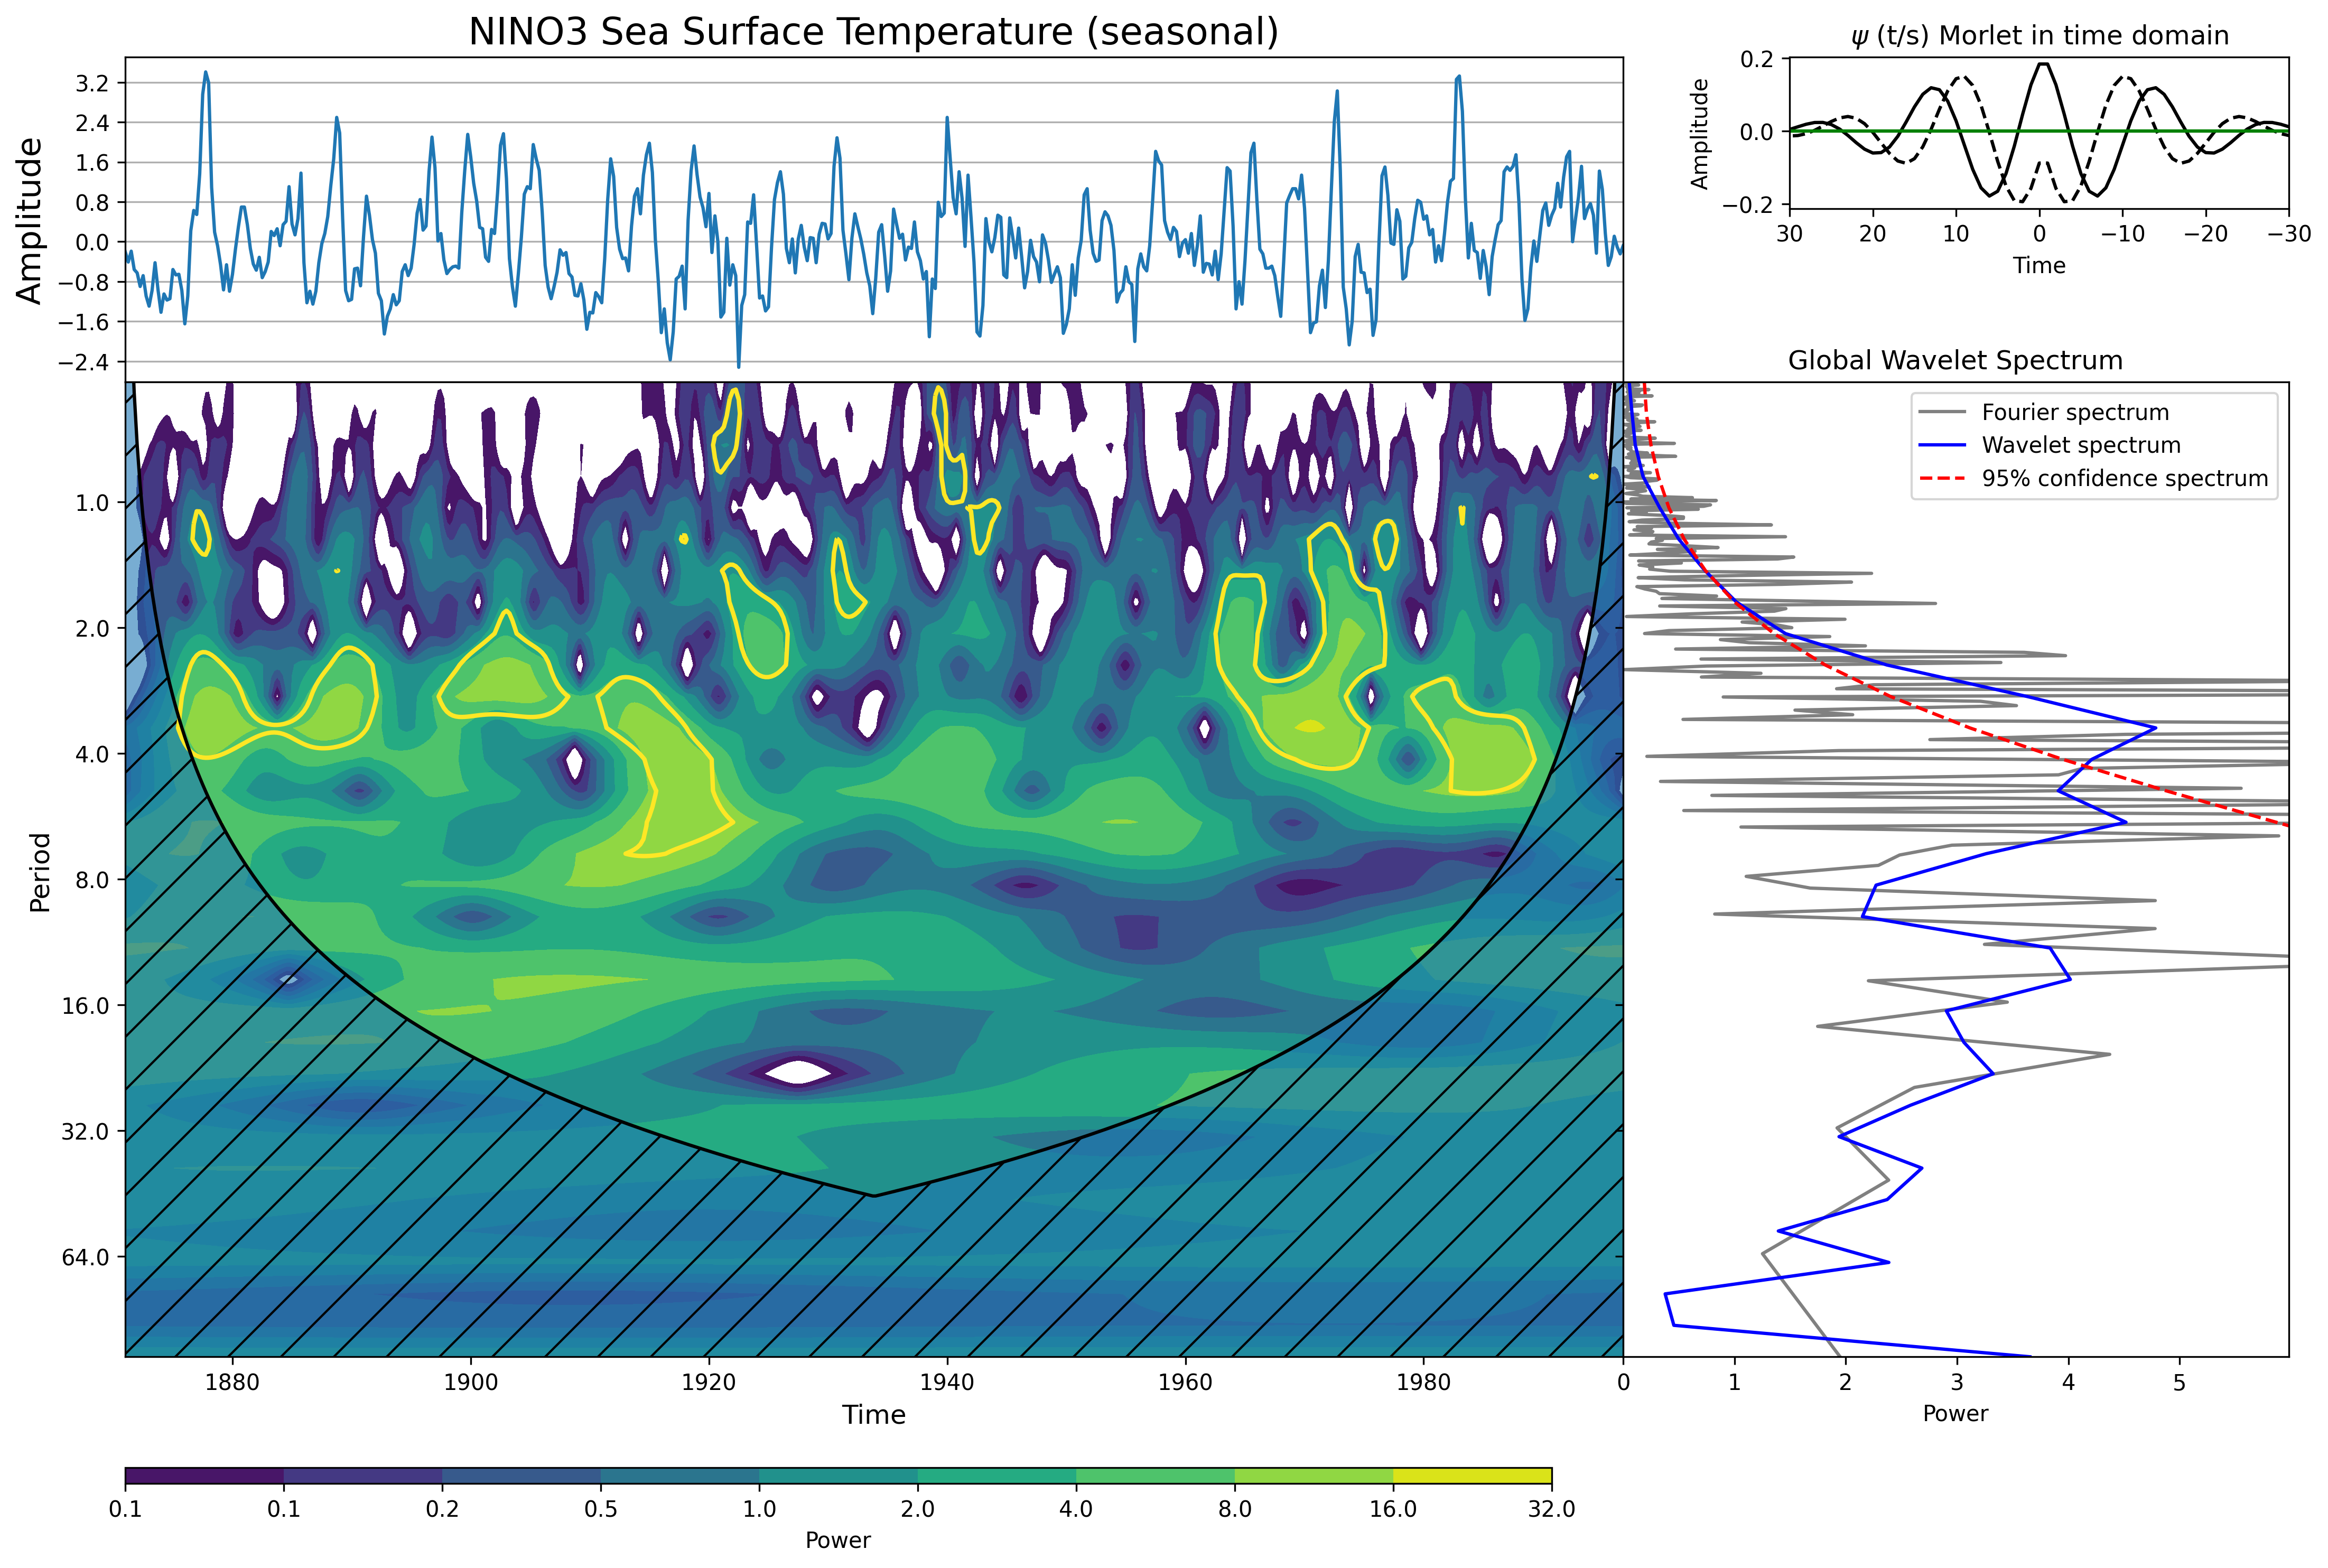

In [3]:
import waipy
N =504      # the time series of length N.

dt = 1/4    # amount of time between each time series value, i.e. the sampling time.
            # seasonal data 1/4 year - 4 measures in 1 year

T1 = 1871.  # start time
data,time = waipy.load_txt('../lib/waipy/data/txt/sst_nino3.dat',dt,T1)
print (len(data))
data_norm = waipy.normalize(data)
pad = 1         # pad the time series with zeroes (recommended)
dj = 0.25       # this will do 4 sub-octaves per octave
s0 = 2*dt       # this says start at a scale of 6 months if dt =annual
j1 = 7/dj       # this says do 7 powers-of-two with dj sub-octaves each
lag1 = 0.72     # lag-1 autocorrelation for red noise background
param = 6
mother = 'Morlet'
dt = 1/4.

result = waipy.cwt(data_norm, dt, pad, dj, s0, j1, lag1, param, mother='Morlet',name='Nino3')
var='NINO3 Sea Surface Temperature (seasonal)'
#time from waipy.load_txt 
#data normalize
dtmin = 0.25/8    # dt/n of suboctaves
waipy.wavelet_plot(var, time, data_norm, dtmin, result)


### 2) Let's ask for valid data - inside COI

Just that simple!

In [4]:
import numpy as np
import numpy.ma as ma
xm,ym = result['power'].shape
# create a masked matrix
mask_COI = ma.masked_all((xm,ym))
# range values in x,y
for i in range(xm):
    for j in range(ym):
        # ask if the value in x is under the dome of COI
        if ( np.log2(result['period'][i])<= np.log2(result['coi'][j])):
            # Now save the valid data in your masked array
            mask_COI[i,j] = result['power'][i,j]


### 3) Plot and check


%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


/usr/local/lib/python3.9/site-packages/IPython/core/magics/pylab.py:162: UserWarning: pylab import has clobbered these variables: ['var', 'time', 'pad']
`%matplotlib` prevents importing * from pylab and numpy
  warn("pylab import has clobbered these variables: %s"  % clobbered +
/var/folders/ny/rns38jpd49n3tx3lmhwlqx_80000gn/T/ipykernel_951/1340840557.py:29: RuntimeWarning: divide by zero encountered in log2
  pc=ax.contourf(time,np.log2(result['period']) ,np.log2(mask_COI), np.log2(lev), cmap=cmap)
/var/folders/ny/rns38jpd49n3tx3lmhwlqx_80000gn/T/ipykernel_951/1340840557.py:29: RuntimeWarning: invalid value encountered in log2
  pc=ax.contourf(time,np.log2(result['period']) ,np.log2(mask_COI), np.log2(lev), cmap=cmap)


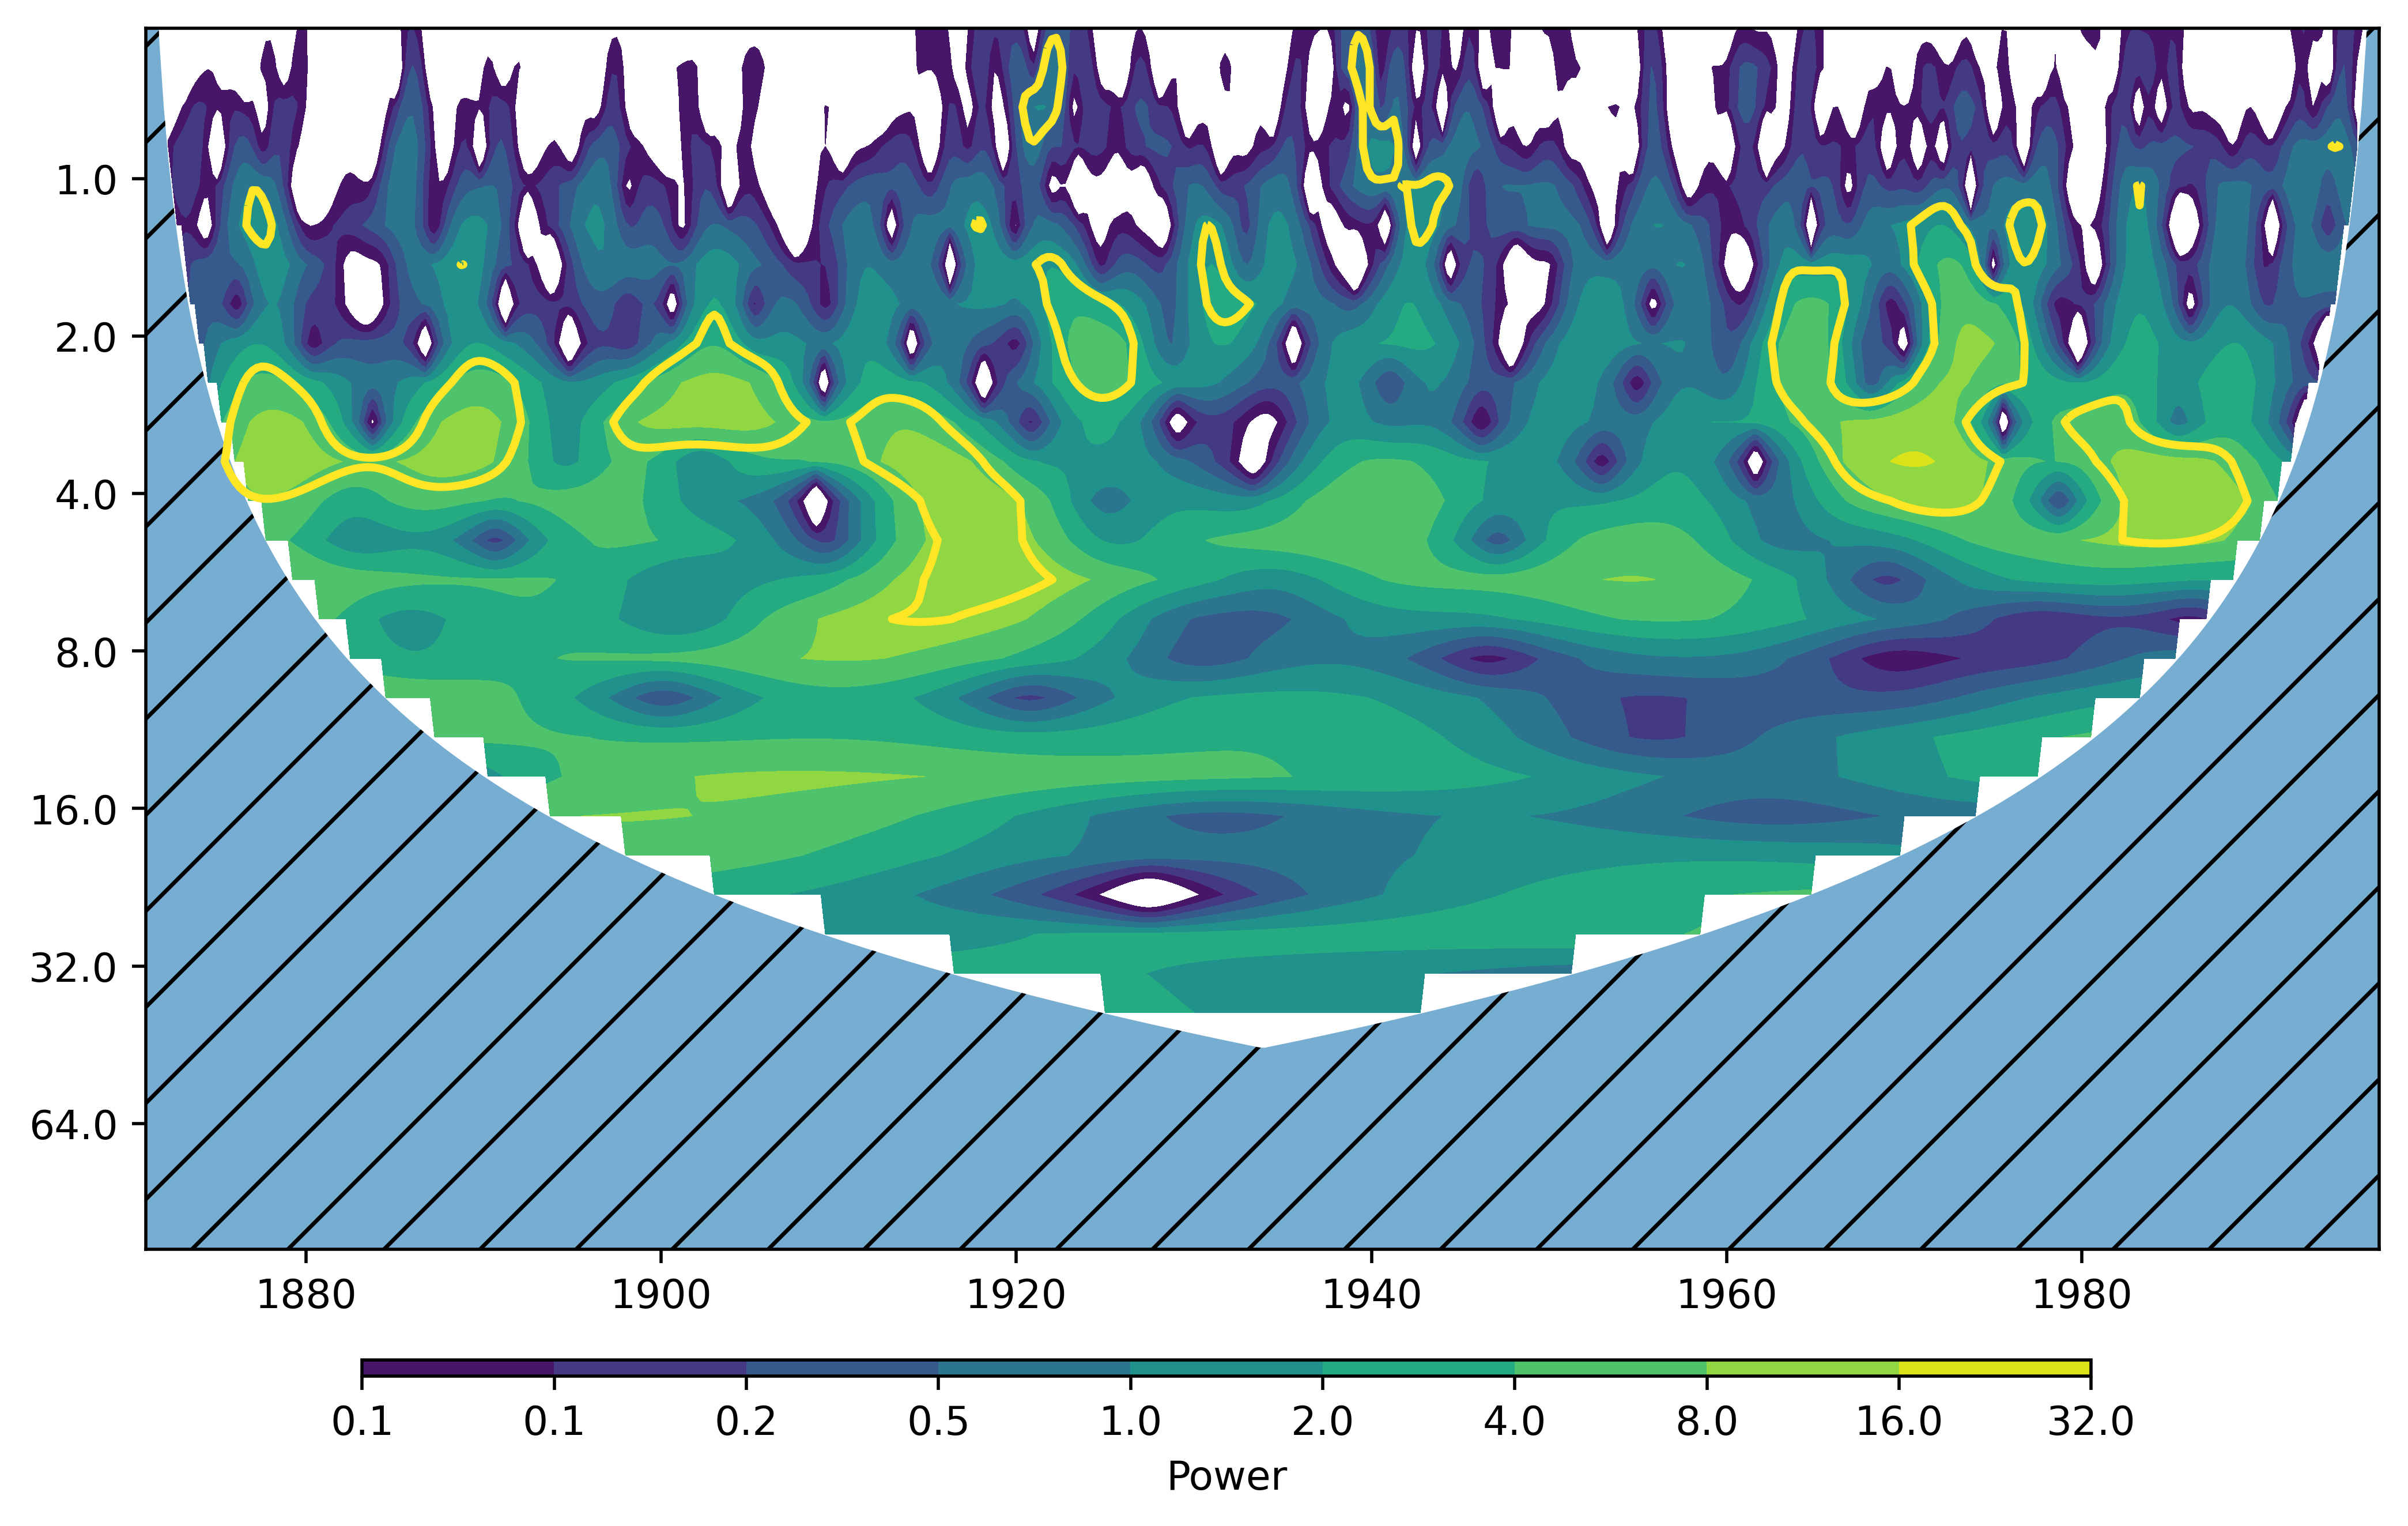

In [5]:
%pylab inline

from matplotlib.pyplot import *
def levels(result, dtmin):
    """
    Power levels
    """

    dtmax = result['power'].max()
    lev = []
    for i in range(int(log2(dtmax / dtmin)) + 1):
        dtmin = dtmin * 2
        lev.append(dtmin)
    return lev

lev = levels(result, dtmin)
cmap = mpl.cm.get_cmap('viridis')
#cmap.set_over('yellow')
#cmap.set_under('cyan')
#cmap.set_bad('red')

yt = range(int(np.log2(result['period'][0])),int(np.log2(result['period'][-1]) + 1))
Yticks = [float(math.pow(2, p)) for p in yt]  # make 2^periods

fig = plt.figure(figsize=(10,5.5), dpi=500)

ax = subplot(1,1,1)
data,time = waipy.load_txt('../lib/waipy/data/txt/sst_nino3.dat',dt,T1)
pc=ax.contourf(time,np.log2(result['period']) ,np.log2(mask_COI), np.log2(lev), cmap=cmap)
ax.contour(time,np.log2(result['period'] ),result['sig95'],[-99, 1],linewidths=2)
ax.set_yticks(yt)
ax.set_yticklabels(Yticks)
ax.set_ylim(ax.get_ylim()[::-1])


ax.fill_between(time,np.log2(result['coi']),int(np.log2(result['period'][-1]) + 1),alpha=0.6,hatch='/')


position = fig.add_axes([0.2, 0.03, 0.6, 0.01])
def cb_formatter(x, pos):
    # x is in base 2
    linear_number = 2 ** x
    return '{:.1f}'.format(linear_number)

cbar = plt.colorbar(
    pc, cax=position, orientation='horizontal',
    format=mpl.ticker.FuncFormatter(cb_formatter),
    )
cbar.set_label('Power')